# CRC external validation — pan-cancer Hist2Pheno

One HE BigTIFF (`Visium_V2_Human_Colon_Cancer_P2_tissue_image`), StarDist nuclei, **no cell-type ground truth** and no 10x JSON.
Predictions are the pan-cancer **cross-section** checkpoint
`D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

OME `PhysicalSize` is **0.274 µm/px** (20×). The 96 dpi tag is a placeholder and is not used.
A native 16 px crop is ~4.38 µm, so features are shrunk onto the 0.5 µm/px grid (`scale ≈ 0.548`) before the 16 px / 8 µm UNI crop.

```bash
cd /home/lingyu/ssd2/Python/Hist2Pheno
bash code/External_val/CRC/demo.sh dry-run
CUDA_DEVICE=2 bash code/External_val/CRC/demo.sh all
```

Outputs: `data/Visium/CRC/pred_pancancer_section/`.
Screen output and elapsed time: `code/External_val/CRC/CRC.log`.


In [8]:
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))

from Hist2Pheno_pkg.external_validation import ExternalCohort

_cohort = ExternalCohort(
    name="CRC",
    data_root=REPO / "data" / "Visium" / "CRC",
    repo=REPO,
    he_suffix=".btf",
)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.0

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px ({g.get('mpp_source', '')})  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")


Visium_V2_Human_Colon_Cancer_P2_tissue_image  mpp=0.2738 µm/px (OME PhysicalSize)  native16=4.38 µm  after rescale=8.0 µm  scale=0.5475
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/CRC/pred_pancancer_section/Visium_V2_Human_Colon_Cancer_P2_tissue_image/Visium_V2_Human_Colon_Cancer_P2_tissue_image_stardist_pred.h5ad


In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: bash code/External_val/CRC/demo.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


,fraction,mean_conf,n
sample,Visium_V2_Human_Colon_Cancer_P2_tissue_image,Visium_V2_Human_Colon_Cancer_P2_tissue_image,Visium_V2_Human_Colon_Cancer_P2_tissue_image
class,,,
Endothelial,0.683,0.515,340879.0
Immune,0.281,0.434,140320.0
Stromal,0.020,0.373,10100.0
Epithelial,0.015,0.422,7495.0
Neural,0.000,0.356,1.0



===== L12 =====


,fraction,mean_conf,n
sample,Visium_V2_Human_Colon_Cancer_P2_tissue_image,Visium_V2_Human_Colon_Cancer_P2_tissue_image,Visium_V2_Human_Colon_Cancer_P2_tissue_image
class,,,
Myeloid,0.626,0.361,312381.0
T_cell,0.222,0.337,110719.0
Endothelial,0.125,0.351,62201.0
Stromal,0.021,0.298,10453.0
B_Plasma,0.002,0.361,1125.0
Tumor,0.002,0.390,981.0
Epithelial,0.002,0.330,935.0



===== L2 =====


,fraction,mean_conf,n
sample,Visium_V2_Human_Colon_Cancer_P2_tissue_image,Visium_V2_Human_Colon_Cancer_P2_tissue_image,Visium_V2_Human_Colon_Cancer_P2_tissue_image
class,,,
Endothelial,0.394,0.248,196513.0
Neutrophil,0.234,0.236,116548.0
CD4_T,0.155,0.190,77170.0
B_cell,0.101,0.248,50129.0
Fibroblast,0.074,0.190,37077.0
Macrophage,0.016,0.166,7737.0
Epithelial,0.010,0.225,4790.0
Tumor,0.007,0.254,3511.0


[plot] Visium_V2_Human_Colon_Cancer_P2_tissue_image  nuclei=498,795  neighbor=22.9px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.0  rows=HE+points


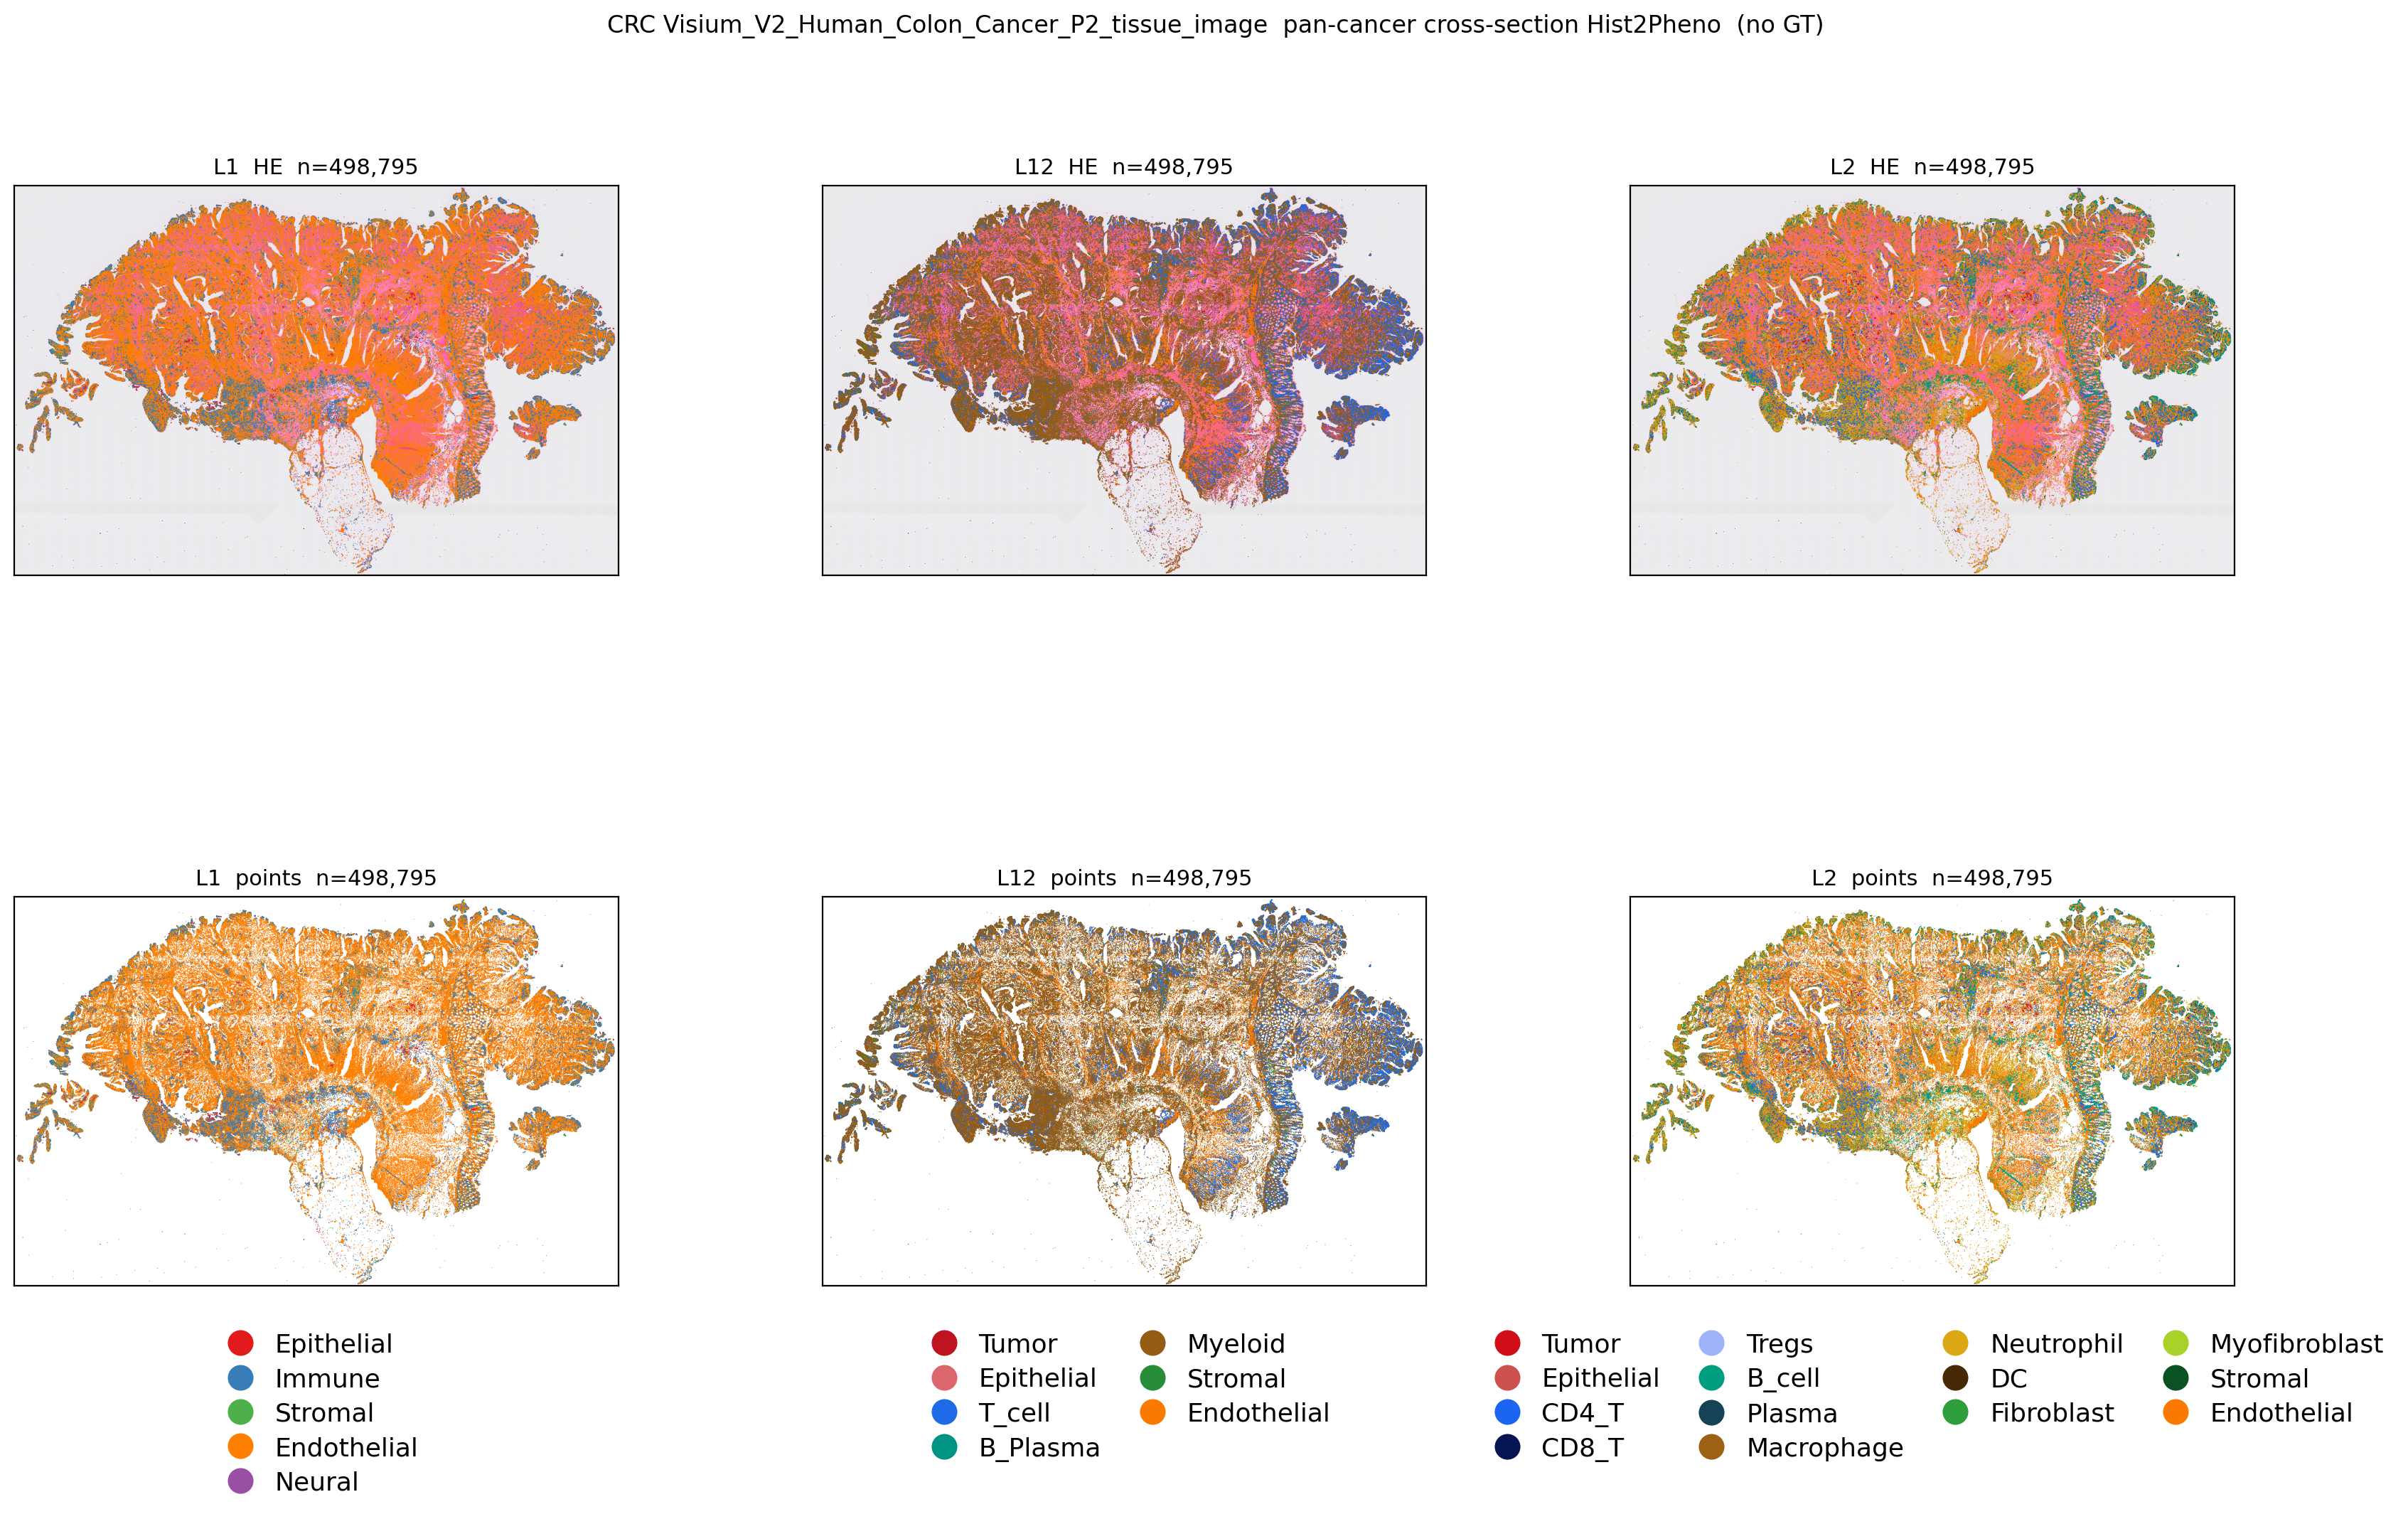

In [9]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


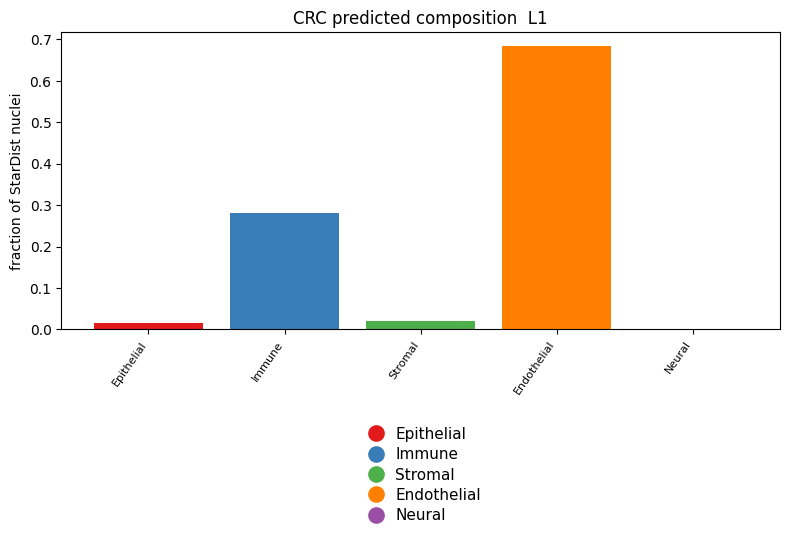

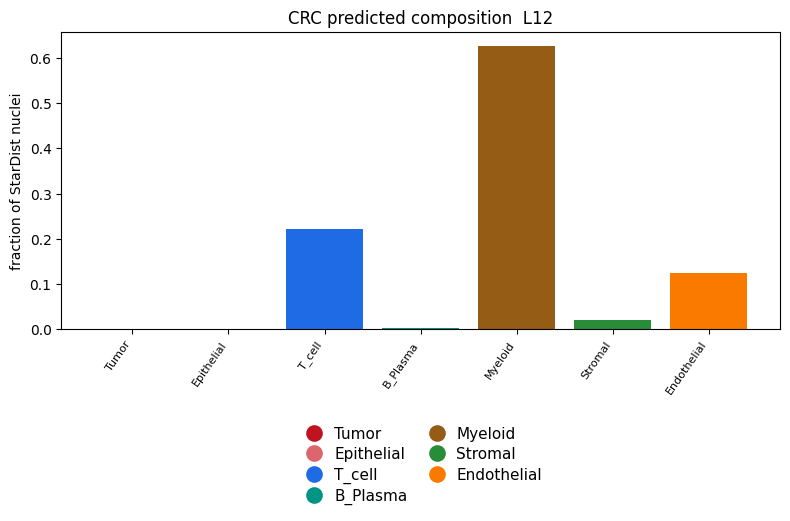

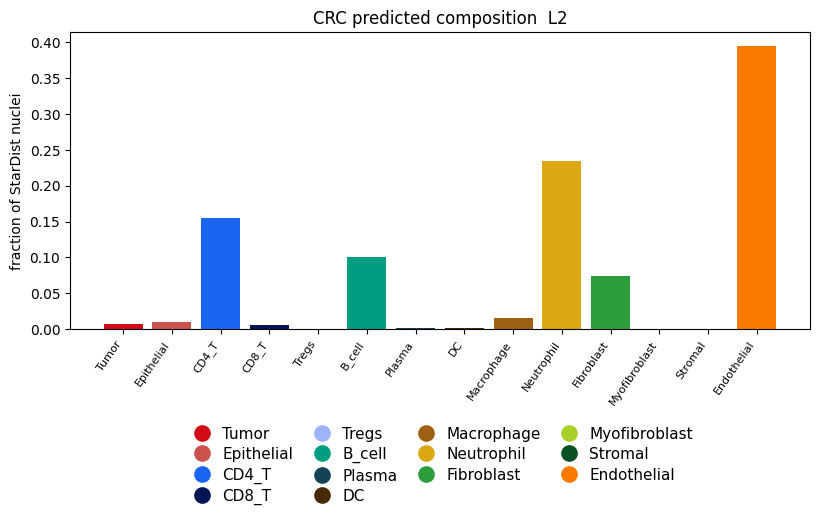

In [4]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native BigTIFF pixels, so R = **55 µm** is converted with this slide's OME µm/px (~0.274), not with 96 dpi and not with 0.5. TLS, SRI, and TNI each use a 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidates.


In [5]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

CRC_NICHE = OrganNicheConfig(
    pan_organ="pancancer_crc",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="CRC",
)
display(hni.index_formula_table(CRC_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [6]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, CRC_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, CRC_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, CRC_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )


[niche] cache Visium_V2_Human_Colon_Cancer_P2_tissue_image_niche_indices.h5ad  n=498,795  µm/px=0.2738
  TLS hotspot: {'n_cells_total': 498795, 'n_candidate_cells': 24940, 'fraction_candidate': 0.050000501207911066, 'max_tls_spatial': 0.19651782091461717, 'mean_tls_spatial_candidate': 0.16134638614118557, 'centroid_x': 46960.61192845618, 'centroid_y': 23067.466250076384}
  mean TLS=0.393  TLS_spatial=0.119  SRI=11.626  TNI=46.262


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/CRC/pred_pancancer_section/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,Visium_V2_Human_Colon_Cancer_P2_tissue_image,498795,0.393,0.393,0.568,0.902,0.119,0.121,0.153,0.197,0.698,0.682,0.215,0.353,0.147,0.533


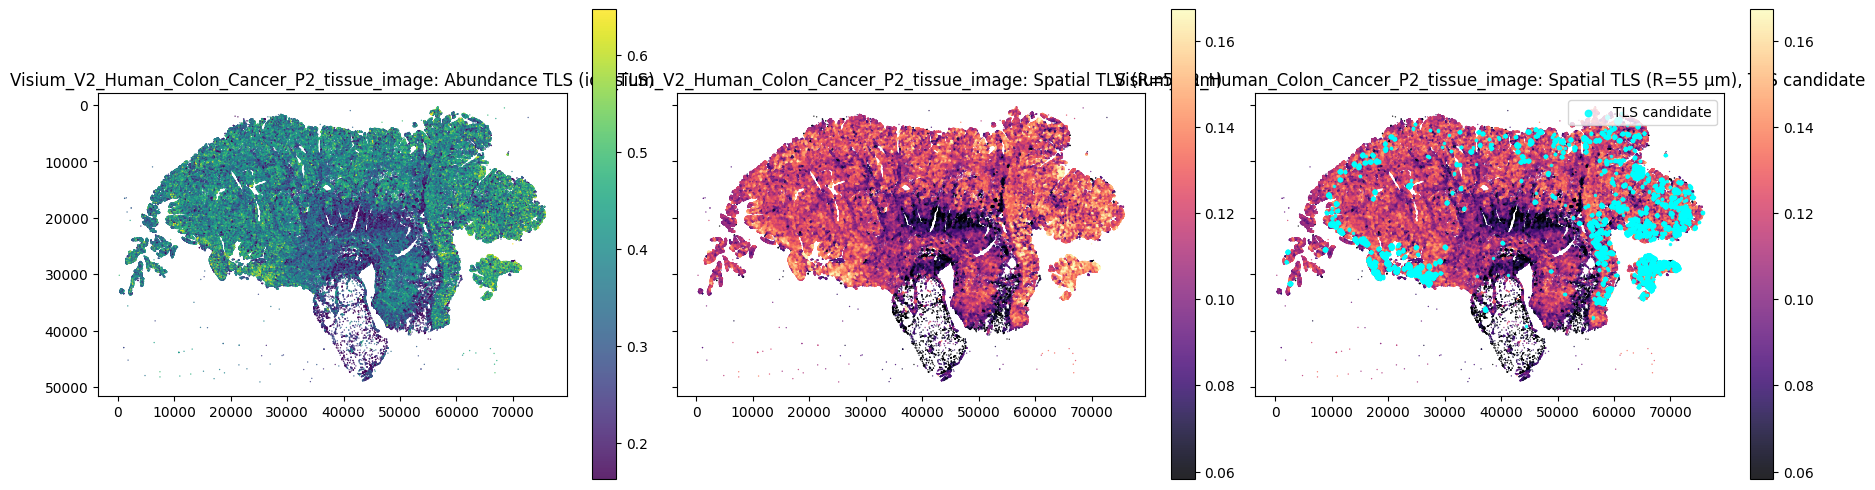

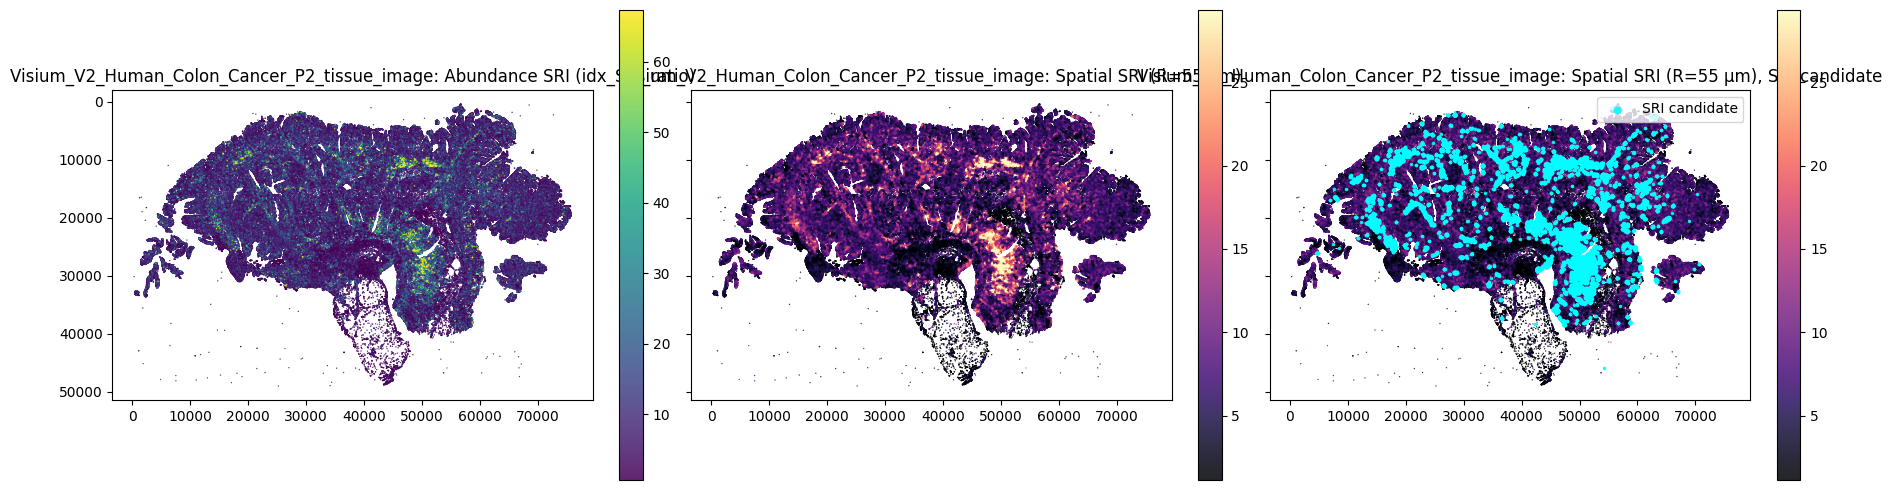

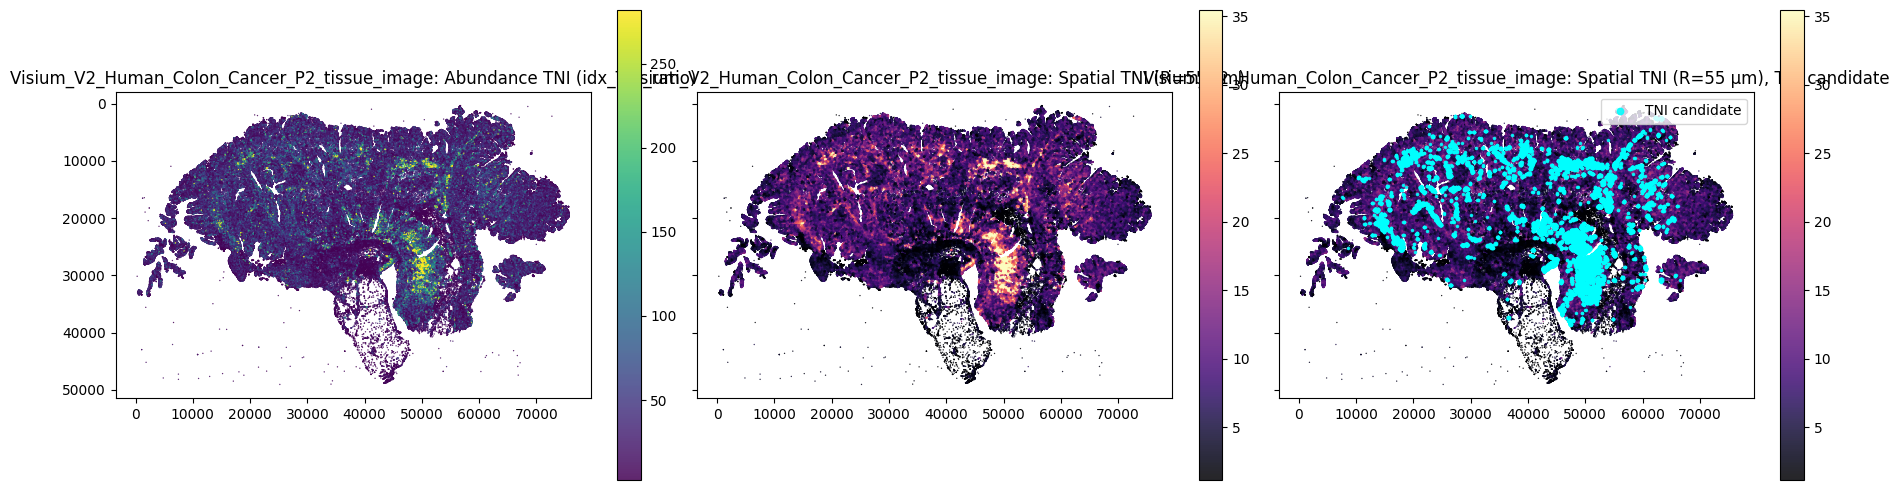

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
